In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

df = pd.read_csv("diabetes.csv")

print("Dataset loaded successfully!")
print(df.head())


Dataset loaded successfully!
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  


In [3]:

print("Dataset Information:")
df.info()

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nStatistical Description:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Pregnancies    768 non-null    int64  
 1   Glucose        768 non-null    int64  
 2   BloodPressure  768 non-null    int64  
 3   SkinThickness  768 non-null    int64  
 4   Insulin        768 non-null    int64  
 5   BMI            768 non-null    float64
 6   Pedigree       768 non-null    float64
 7   Age            768 non-null    int64  
 8   Outcome        768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Dataset Shape:
(768, 9)

Column Names:
Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'Pedigree', 'Age', 'Outcome'],
      dtype='object')

Statistical Description:
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768

In [4]:

X = df.drop('Outcome', axis=1)
y = df['Outcome']

print("Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())


Features:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  
0     0.627   50  
1     0.351   31  
2     0.672   32  
3     0.167   21  
4     2.288   33  

Target Variable:
0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64


In [5]:

# Replace invalid zero values with NaN
zero_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

X[zero_columns] = X[zero_columns].replace(0, np.nan)

# Replace missing values using median
imputer = SimpleImputer(strategy='median')

X[zero_columns] = imputer.fit_transform(X[zero_columns])

print("Data preprocessing completed!")
print("\nMissing Values After Preprocessing:")
print(X.isnull().sum())


Data preprocessing completed!

Missing Values After Preprocessing:
Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
dtype: int64


In [6]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (537, 8)
Testing Data: (231, 8)


In [7]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature normalization completed!")


Feature normalization completed!


In [8]:

k = 5

knn = KNeighborsClassifier(n_neighbors=k)

knn.fit(X_train_scaled, y_train)

print("KNN Model Trained Successfully!")


KNN Model Trained Successfully!


In [9]:

y_pred = knn.predict(X_test_scaled)

print("Predicted Values:")
print(y_pred)

print("\nActual Values:")
print(y_test.values)


Predicted Values:
[0 0 1 1 0 0 1 0 0 0 0 0 0 1 1 1 1 0 1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 1 0
 0 0 0 0 1 0 0 0 1 0 1 0 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1 1 0 0
 0 1 1 0 0 0 0 0 0 0 0 1 0 1 1 0 1 1 0 1 1 1 1 0 1 0 0 0 1 0 0 0 0 1 0 0 0
 1 0 1 1 0 0 0 0 1 0 0 1 0 0 0 1 0 1 0 0 0 0 1 0 1 0 0 0 1 0 0 0 1 1 1 0 0
 0 0 1 0 0 1 0 1 0 1 0 0 1 0 0 0 0 0 0 0 1 0 0 1 1 0 0 1 1 0 0 0 0 1 0 1 1
 0 0 0 0 1 0 0 0 0 0 1 1 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 1 1
 0 0 0 1 0 1 0 1 0]

Actual Values:
[1 1 1 1 1 0 0 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 0 1 1 0 0 1 1 0 0 0 1 0
 1 0 0 0 1 0 0 0 1 0 1 0 0 0 0 1 0 1 1 0 1 1 1 0 0 1 1 0 0 0 0 0 0 1 1 0 0
 0 1 1 0 1 0 0 0 0 0 0 0 1 1 1 0 1 1 0 1 1 0 1 0 1 0 0 0 1 1 1 0 0 0 0 0 1
 1 1 1 0 0 0 0 0 1 0 1 1 0 1 0 1 0 1 0 0 0 0 0 1 1 0 0 0 1 1 1 0 1 1 0 0 0
 1 0 0 1 0 0 1 0 1 0 0 0 0 1 0 0 0 0 0 1 1 0 0 1 0 0 0 1 1 0 0 0 1 0 0 1 1
 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 1 0 0 0 0 0 1 0 0 0 1 0 0 0 0 1
 0 0 1 0 0 0 0 1 1]


In [10]:

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[125  25]
 [ 34  47]]


In [11]:

accuracy = accuracy_score(y_test, y_pred)

error_rate = 1 - accuracy

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

print("Accuracy:", accuracy)
print("Error Rate:", error_rate)
print("Precision:", precision)
print("Recall:", recall)


Accuracy: 0.7445887445887446
Error Rate: 0.2554112554112554
Precision: 0.6527777777777778
Recall: 0.5802469135802469


In [12]:

print("Classification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.83      0.81       150
           1       0.65      0.58      0.61        81

    accuracy                           0.74       231
   macro avg       0.72      0.71      0.71       231
weighted avg       0.74      0.74      0.74       231



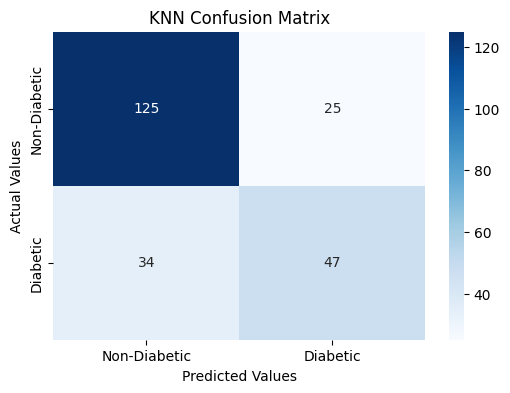

In [13]:

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Diabetic', 'Diabetic'],
    yticklabels=['Non-Diabetic', 'Diabetic']
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()
